In [2]:
!pip install pandas numpy matplotlib seaborn

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
np.random.seed(42)

n = 500

departments = [
    "HR", "IT", "Finance",
    "Marketing", "Operations"
]

genders = ["Male", "Female"]

statuses = [
    "Active", "Inactive", "On Leave"
]

data = {
    "Employee_ID": [
        f"EMP{i:04d}" for i in range(1, n + 1)
    ],

    "EmployeeName": [
        f"Employee{i}" for i in range(1, n + 1)
    ],

    "Age": np.random.randint(21, 60, n),

    "Gender": np.random.choice(
        genders, n
    ),

    "Department": np.random.choice(
        departments, n
    ),

    "Salary": np.random.randint(
        20000, 120000, n
    ),

    "Experience_Years": np.random.randint(
        0, 35, n
    ),

    "Job_Satisfaction": np.random.randint(
        1, 6, n
    ),

    "Employment_Status": np.random.choice(
        statuses, n
    ),

    "Joining_Date": pd.date_range(
        start="2018-01-01",
        periods=n,
        freq="D"
    ).astype(str)
}

df = pd.DataFrame(data)

print("Dataset created successfully!")
print("Shape:", df.shape)

df.head()


Dataset created successfully!
Shape: (500, 10)


,Employee_ID,EmployeeName,Age,Gender,Department,Salary,Experience_Years,Job_Satisfaction,Employment_Status,Joining_Date
0,EMP0001,Employee1,59,Male,Finance,77775,27,1,On Leave,2018-01-01
1,EMP0002,Employee2,49,Male,Finance,110816,14,1,Active,2018-01-02
2,EMP0003,Employee3,35,Female,Operations,110093,5,3,Active,2018-01-03
3,EMP0004,Employee4,28,Female,Marketing,55400,19,4,Active,2018-01-04
4,EMP0005,Employee5,41,Male,IT,24494,13,2,On Leave,2018-01-05


In [8]:
df.loc[10:25, "Age"] = np.nan
df.loc[30:45, "Salary"] = np.nan
df.loc[50:60, "Department"] = np.nan
df.loc[70:80, "Job_Satisfaction"] = np.nan

#Introduce inconsistent department names
df.loc[100:105, "Department"] = " it "
df.loc[106:110, "Department"] = "finance"

#Introduce inconsistent gender formatting
df.loc[120:125, "Gender"] = "female"
df.loc[126:130, "Gender"] = " MALE "

#Introduce inconsistent employment status
df.loc[140:145, "Employment_Status"] = "active"
df.loc[146:150, "Employment_Status"] = "ON LEAVE"

#Introduce invalid values
df.loc[160, "Age"] = 150
df.loc[161, "Salary"] = -5000
df.loc[162, "Experience_Years"] = -2
df.loc[163, "Job_Satisfaction"] = 8

#Introduce duplicates
df = pd.concat(
    [df, df.iloc[:10]],
    ignore_index=True
)

#Introduce inconsistent date formats
df.loc[170:175, "Joining_Date"] = "12/05/2022"

#Save the raw dataset
df.to_csv("employee_data_raw.csv", index=False)

print("Messy dataset created!")
print("Total records:", len(df))


Messy dataset created!
Total records: 510


In [9]:
import os

print(os.getcwd())

C:\Users\ADITI


In [10]:
df.head (10)


,Employee_ID,EmployeeName,Age,Gender,Department,Salary,Experience_Years,Job_Satisfaction,Employment_Status,Joining_Date
0,EMP0001,Employee1,59.0,Male,Finance,77775.0,27,1.0,On Leave,2018-01-01
1,EMP0002,Employee2,49.0,Male,Finance,110816.0,14,1.0,Active,2018-01-02
2,EMP0003,Employee3,35.0,Female,Operations,110093.0,5,3.0,Active,2018-01-03
3,EMP0004,Employee4,28.0,Female,Marketing,55400.0,19,4.0,Active,2018-01-04
4,EMP0005,Employee5,41.0,Male,IT,24494.0,13,2.0,On Leave,2018-01-05
5,EMP0006,Employee6,59.0,Female,Marketing,100688.0,1,1.0,Active,2018-01-06
6,EMP0007,Employee7,39.0,Male,Marketing,109431.0,8,2.0,Active,2018-01-07
7,EMP0008,Employee8,43.0,Female,Finance,94691.0,19,4.0,Active,2018-01-08
8,EMP0009,Employee9,31.0,Male,Marketing,117419.0,25,4.0,Active,2018-01-09
9,EMP0010,Employee10,31.0,Male,HR,63001.0,28,5.0,Active,2018-01-10


In [11]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
df.info()

Rows: 510
Columns: 10
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 510 entries, 0 to 509
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Employee_ID        510 non-null    object 
 1   EmployeeName       510 non-null    object 
 2   Age                494 non-null    float64
 3   Gender             510 non-null    object 
 4   Department         499 non-null    object 
 5   Salary             494 non-null    float64
 6   Experience_Years   510 non-null    int32  
 7   Job_Satisfaction   499 non-null    float64
 8   Employment_Status  510 non-null    object 
 9   Joining_Date       510 non-null    object 
dtypes: float64(3), int32(1), object(6)
memory usage: 38.0+ KB


In [12]:
missing_values = df.isnull().sum()

print("Missing values per column:")
print(missing_values)
print(
    "Duplicate records:",
    df.duplicated().sum()
)
df.describe()

Missing values per column:
Employee_ID           0
EmployeeName          0
Age                  16
Gender                0
Department           11
Salary               16
Experience_Years      0
Job_Satisfaction     11
Employment_Status     0
Joining_Date          0
dtype: int64
Duplicate records: 10


,Age,Salary,Experience_Years,Job_Satisfaction
count,494.000000,494.000000,510.000000,499.000000
mean,41.222672,70843.293522,16.678431,3.040080
std,12.393932,28688.215662,10.211445,1.412223
min,21.000000,-5000.000000,-2.000000,1.000000
25%,31.000000,46637.500000,8.000000,2.000000
50%,42.000000,69858.000000,17.000000,3.000000
75%,51.000000,96164.500000,25.000000,4.000000
max,150.000000,119986.000000,34.000000,8.000000


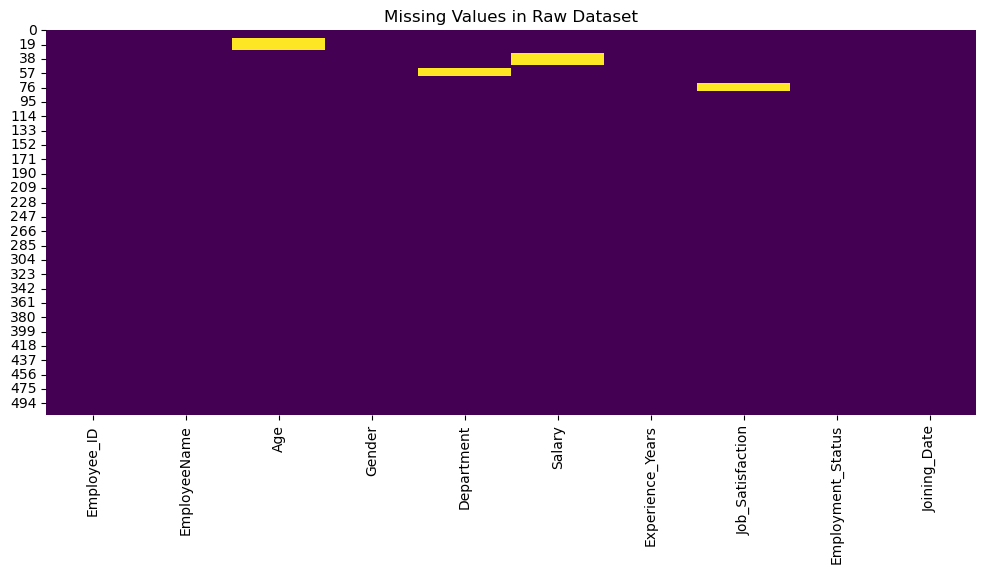

In [13]:
plt.figure(figsize=(12, 5))

sns.heatmap(
    df.isnull(),
    cbar=False,
    cmap="viridis"
)

plt.title("Missing Values in Raw Dataset")
plt.show()

In [14]:
def data_quality_report(data):

    report = pd.DataFrame({
        "Column": data.columns,

        "Data_Type": [
            str(data[col].dtype)
            for col in data.columns
        ],

        "Missing_Values": [
            data[col].isnull().sum()
            for col in data.columns
        ],

        "Missing_Percentage": [
            round(
                data[col].isnull().mean() * 100, 2
            )
            for col in data.columns
        ],

        "Unique_Values": [
            data[col].nunique()
            for col in data.columns
        ]
    })

    return report


quality_before = data_quality_report(df)

quality_before

,Column,Data_Type,Missing_Values,Missing_Percentage,Unique_Values
0,Employee_ID,object,0,0.00,500
1,EmployeeName,object,0,0.00,500
2,Age,float64,16,3.14,40
3,Gender,object,0,0.00,4
4,Department,object,11,2.16,7
5,Salary,float64,16,3.14,483
6,Experience_Years,int32,0,0.00,36
7,Job_Satisfaction,float64,11,2.16,6
8,Employment_Status,object,0,0.00,5
9,Joining_Date,object,0,0.00,495


In [15]:
def remove_duplicates(data):

    before = len(data)

    cleaned = data.drop_duplicates().copy()

    removed = before - len(cleaned)

    print("Duplicate records removed:", removed)

    return cleaned


df_clean = remove_duplicates(df)

Duplicate records removed: 10


In [16]:
def standardise_text(data):

    data = data.copy()

    text_columns = data.select_dtypes(
        include=["object"]
    ).columns

    for col in text_columns:

        data[col] = data[col].str.strip()

    # Standardise categories
    data["Department"] = (
        data["Department"].str.title()
    )

    data["Gender"] = (
        data["Gender"].str.title()
    )

    data["Employment_Status"] = (
        data["Employment_Status"].str.title()
    )

    return data


df_clean = standardise_text(df_clean)

print("Text standardisation completed!")

Text standardisation completed!


In [17]:
def fix_data_types(data):

    data = data.copy()

    data["Age"] = pd.to_numeric(
        data["Age"], errors="coerce"
    )

    data["Salary"] = pd.to_numeric(
        data["Salary"], errors="coerce"
    )

    data["Experience_Years"] = pd.to_numeric(
        data["Experience_Years"], errors="coerce"
    )

    data["Job_Satisfaction"] = pd.to_numeric(
        data["Job_Satisfaction"], errors="coerce"
    )

    data["Joining_Date"] = pd.to_datetime(
        data["Joining_Date"],
        format="mixed",
        dayfirst=True,
        errors="coerce"
    )

    return data


df_clean = fix_data_types(df_clean)

print(df_clean.dtypes)


Employee_ID                  object
EmployeeName                 object
Age                         float64
Gender                       object
Department                   object
Salary                      float64
Experience_Years              int32
Job_Satisfaction            float64
Employment_Status            object
Joining_Date         datetime64[ns]
dtype: object


In [18]:
def handle_invalid_values(data):

    data = data.copy()

    data.loc[
        ~data["Age"].between(18, 65),
        "Age"
    ] = np.nan

    data.loc[
        data["Salary"] <= 0,
        "Salary"
    ] = np.nan

    data.loc[
        ~data["Experience_Years"].between(0, 50),
        "Experience_Years"
    ] = np.nan

    data.loc[
        ~data["Job_Satisfaction"].between(1, 5),
        "Job_Satisfaction"
    ] = np.nan

    return data


df_clean = handle_invalid_values(df_clean)

print("Invalid values handled!")


Invalid values handled!


In [19]:
def handle_missing_values(data):

    data = data.copy()

    numerical_columns = [
        "Age",
        "Salary",
        "Experience_Years",
        "Job_Satisfaction"
    ]

    categorical_columns = [
        "Gender",
        "Department",
        "Employment_Status"
    ]

    # Fill numerical missing values
    for col in numerical_columns:

        data[col] = data[col].fillna(
            data[col].median()
        )

    # Fill categorical missing values
    for col in categorical_columns:

        data[col] = data[col].fillna(
            data[col].mode()[0]
        )

    return data


df_clean = handle_missing_values(df_clean)

print("Missing values handled!")


Missing values handled!


In [20]:
def clean_employee_data(data):

    cleaned = data.copy()

    cleaned = remove_duplicates(cleaned)

    cleaned = standardise_text(cleaned)

    cleaned = fix_data_types(cleaned)

    cleaned = handle_invalid_values(cleaned)

    cleaned = handle_missing_values(cleaned)

    return cleaned


df_clean = clean_employee_data(df)

print("DATA CLEANING COMPLETED!")


Duplicate records removed: 10
DATA CLEANING COMPLETED!


In [21]:
#Save cleaned dataset
df_clean.to_csv(
    "employee_data_cleaned.csv",
    index=False
)

print("Cleaned dataset exported successfully!")


Cleaned dataset exported successfully!


In [30]:
quality_before = data_quality_report(df)

quality_before.to_csv(
    "quality_report_before.csv",
    index=False
)

print("Before-cleaning report saved!")

Before-cleaning report saved!


In [22]:
#Quality report after cleaning
quality_after = data_quality_report(df_clean)

quality_after.to_csv(
    "quality_report_after.csv",
    index=False
)

print("Quality reports generated!")

Quality reports generated!


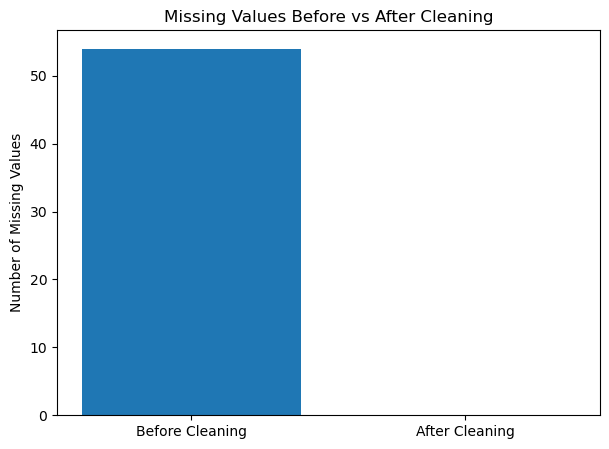

In [23]:
before_missing = df.isnull().sum().sum()
after_missing = df_clean.isnull().sum().sum()

plt.figure(figsize=(7, 5))

plt.bar(
    ["Before Cleaning", "After Cleaning"],
    [before_missing, after_missing]
)

plt.title("Missing Values Before vs After Cleaning")
plt.ylabel("Number of Missing Values")

plt.show()


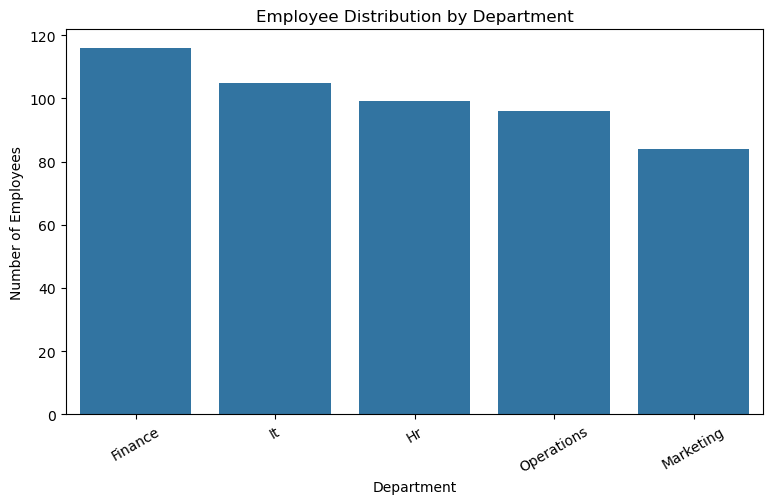

In [24]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df_clean,
    x="Department",
    order=df_clean["Department"].value_counts().index
)

plt.title("Employee Distribution by Department")
plt.xlabel("Department")
plt.ylabel("Number of Employees")

plt.xticks(rotation=30)

plt.show()

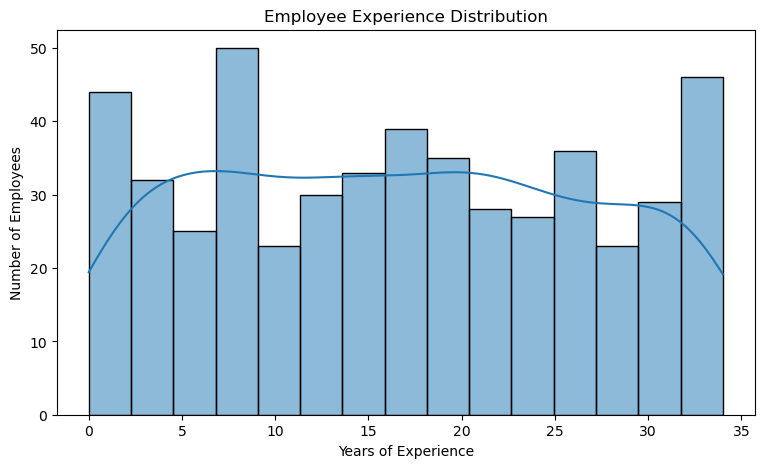

In [25]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df_clean,
    x="Experience_Years",
    bins=15,
    kde=True
)

plt.title("Employee Experience Distribution")
plt.xlabel("Years of Experience")
plt.ylabel("Number of Employees")

plt.show()

In [26]:
summary = {
    "Total_Records_Before": len(df),
    "Total_Records_After": len(df_clean),

    "Duplicate_Records_Removed":
        df.duplicated().sum(),

    "Missing_Values_Before":
        df.isnull().sum().sum(),

    "Missing_Values_After":
        df_clean.isnull().sum().sum(),

    "Average_Salary":
        round(df_clean["Salary"].mean(), 2),

    "Median_Salary":
        round(df_clean["Salary"].median(), 2),

    "Average_Age":
        round(df_clean["Age"].mean(), 2),

    "Average_Experience":
        round(df_clean["Experience_Years"].mean(), 2)
}

summary_df = pd.DataFrame(
    summary.items(),
    columns=["Metric", "Value"]
)

summary_df


,Metric,Value
0,Total_Records_Before,510.00
1,Total_Records_After,500.00
2,Duplicate_Records_Removed,10.00
3,Missing_Values_Before,54.00
4,Missing_Values_After,0.00
5,Average_Salary,70645.63
6,Median_Salary,69708.00
7,Average_Age,41.03
8,Average_Experience,16.73


In [27]:
summary_df.to_csv(
    "automated_summary_report.csv",
    index=False
)

print("Automated report generated!")

Automated report generated!


In [28]:
#TEST 1: No duplicate records
assert df_clean.duplicated().sum() == 0

#TEST 2: No missing values
assert df_clean.isnull().sum().sum() == 0

#TEST 3: No invalid ages
assert df_clean["Age"].between(18, 65).all()

#TEST 4: No negative salaries
assert (df_clean["Salary"] > 0).all()

#TEST 5: Valid job satisfaction scores
assert df_clean["Job_Satisfaction"].between(1, 5).all()

#TEST 6: Valid employment categories
assert set(df_clean["Employment_Status"].unique()).issubset(
    {"Active", "Inactive", "On Leave"}
)

print("ALL SIX TESTS PASSED!")


ALL SIX TESTS PASSED!


In [29]:
import os

print(os.getcwd())

C:\Users\ADITI
